# 2. Neural-network study

**CSI 4106 Introduction to Artificial Intelligence**  
*Assignment 3: Designing and Diagnosing Neural Networks*  
*Due: November 16, 2026, at 11 PM*

# Identification

Name:  
Student number: Report title:

# 1. Data and objective

The objective is to predict whether an autonomous underwater vehicle
returns before completing its planned survey. The positive class is
`mission_interrupted=1`.

The following cell supplies the imports, feature groups, fixed data
partitions, and an unfitted preprocessing factory used throughout the
assignment. Do not change the supplied feature groups, split settings,
or DataFrame and Series names. You remain responsible for fitting and
applying the preprocessor at the correct stages and for preparing the
NumPy arrays used by Keras.

In [1]:
%pip install tensorflow
from pathlib import Path
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from tensorflow import keras


COMPLETE_URL = (
    "https://raw.githubusercontent.com/turcotte/csi4106-f26/main/"
    "assignments-data/a2/asrc_missions_complete.csv"
)
HIDDEN_URL = (
    "https://raw.githubusercontent.com/turcotte/csi4106-f26/main/"
    "assignments-data/a2/asrc_missions_hidden.csv"
)

COMPLETE_LOCAL_PATH = Path("asrc_missions_complete.csv")
HIDDEN_LOCAL_PATH = Path("asrc_missions_hidden.csv")

TARGET = "mission_interrupted"
NUMERIC_FEATURES = [
    "planned_depth_m",
    "descent_current_speed_m_s",
    "water_temperature_c",
    "sonar_noise_db",
    "navigation_drift_m",
    "battery_health_pct",
    "thruster_vibration_mm_s",
    "missions_since_service",
]
NOMINAL_FEATURES = ["vehicle_class", "seabed_terrain"]
ORDINAL_FEATURES = ["maintenance_grade"]
BINARY_FEATURES = ["firmware_current"]
FEATURES = (
    NUMERIC_FEATURES
    + NOMINAL_FEATURES
    + ORDINAL_FEATURES
    + BINARY_FEATURES
)
EXPECTED_COLUMNS = FEATURES + [TARGET]


def make_preprocessor():
    """Return a new, unfitted copy of the required preprocessor."""
    return ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), NUMERIC_FEATURES),
            (
                "nominal",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                NOMINAL_FEATURES,
            ),
            (
                "ordinal",
                OrdinalEncoder(
                    categories=[["poor", "fair", "good", "excellent"]]
                ),
                ORDINAL_FEATURES,
            ),
            ("binary", "passthrough", BINARY_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


complete_source = COMPLETE_LOCAL_PATH if COMPLETE_LOCAL_PATH.exists() else COMPLETE_URL
missions = pd.read_csv(complete_source)

if list(missions.columns) != EXPECTED_COLUMNS:
    raise ValueError(
        "The complete data do not have the expected columns in the expected order."
    )
if len(missions) != 6371:
    raise ValueError(f"Expected 6,371 labelled missions, got {len(missions):,}.")
if missions.isna().any().any():
    raise ValueError("The complete data contain missing values.")
if not set(missions[TARGET].unique()).issubset({0, 1}):
    raise ValueError("The response must contain only 0 and 1.")

X_labelled = missions[FEATURES].copy()
y_labelled = missions[TARGET].copy()

X_development, X_test, y_development, y_test = train_test_split(
    X_labelled,
    y_labelled,
    test_size=0.20,
    random_state=4106,
    stratify=y_labelled,
)

X_neural_train, X_validation, y_neural_train, y_validation = train_test_split(
    X_development,
    y_development,
    test_size=0.20,
    random_state=4106,
    stratify=y_development,
)

print(f"Loaded labelled data from: {complete_source}")
print(f"Labelled data: {missions.shape}")
print(
    "Partitions: "
    f"neural training={len(X_neural_train)}, "
    f"validation={len(X_validation)}, "
    f"development={len(X_development)}, "
    f"test={len(X_test)}"
)

Note: you may need to restart the kernel to use updated packages.
Loaded labelled data from: https://raw.githubusercontent.com/turcotte/csi4106-f26/main/assignments-data/a2/asrc_missions_complete.csv
Labelled data: (6371, 13)
Partitions: neural training=4076, validation=1020, development=5096, test=1275


## 2.1 Prepare and validate the neural-network inputs

Summarize the complete, development, neural-training, and validation
data as specified in Task 1. Report only the number of reserved test
observations before the final evaluation. Instantiate the supplied
preprocessor, fit it only on the neural-network training predictors, and
transform the validation predictors. Convert predictors and targets to
NumPy arrays suitable for Keras.

Validate and report the array shapes and data types. Confirm that all
values are finite, targets contain only `0` and `1`, and each predictor
array is aligned with its target array. Report the transformed input
width and explain the preprocessing and leakage boundary.

In [2]:
print(f"Shape: {missions.shape}")
print(f"First five rows: \n{missions.head()}")
print(f"complete interrupted count: \n{missions[TARGET].value_counts()}")
print(f"complete interrupted proportion: \n{missions[TARGET].value_counts(normalize=True) * 100}")
print(f"development interrupted count: \n{y_development.value_counts()}")
print(f"development interrupted proportion: \n{y_development.value_counts(normalize=True) * 100}")
print(f"neural-network interrupted count: \n{y_neural_train.value_counts()}")
print(f"neural-network interrupted proportion: \n{y_neural_train.value_counts(normalize=True) * 100}")
print(f"validation interrupted count: \n{y_validation.value_counts()}")
print(f"validation interrupted proportion: \n{y_validation.value_counts(normalize=True) * 100}")

print(f"test number of observations: {len(X_test)}")

processor = make_preprocessor()
neural_processed = processor.fit_transform(X_neural_train)
neural_validation = processor.transform(X_validation)

X_train_np = np.array(neural_processed, dtype=np.float32)
X_validation_np = np.array(neural_validation, dtype=np.float32)
y_train_np = y_neural_train.to_numpy(dtype=np.float32)
y_validation_np = y_validation.to_numpy(dtype=np.float32)

print(f"X_train_np shape: {X_train_np.shape}, X_train_np data type: {X_train_np.dtype}")
print(f"y_train_np shape: {y_train_np.shape}, y_train_np data type: {y_train_np.dtype}")

print(f"X_validation_np shape: {X_validation_np.shape}, X_validation_np data type: {X_validation_np.dtype}")
print(f"y_validation_np shape: {y_validation_np.shape}, y_validation_np data type: {y_validation_np.dtype}")

print(f"X_train_np has finite values: {np.isfinite(X_train_np).all()}")
print(f"y_train_np has finite values: {np.isfinite(y_train_np).all()}")

print(f"X_validation_np has finite values: {np.isfinite(X_validation_np).all()}")
print(f"y_validation_np has finite values: {np.isfinite(y_validation_np).all()}")

print(f"training targets contain only 0 and 1: {np.isin(y_train_np, [0, 1]).all()}")
print(f"validation targets contain only 0 and 1: {np.isin(y_validation_np, [0, 1]).all()}")

print(f"training arrays aligned: {X_train_np.shape[0] == y_train_np.shape[0]}")
print(f"validation arrays aligned: {X_validation_np.shape[0] == y_validation_np.shape[0]}")

print(f"input width: {X_train_np.shape[1]}")

Shape: (6371, 13)
First five rows: 
   planned_depth_m  descent_current_speed_m_s  water_temperature_c  \
0           1400.0                       0.55                  3.3   
1           2700.0                       0.68                  3.0   
2           2870.0                       0.15                  3.6   
3           2840.0                       0.39                  2.5   
4           2430.0                       0.34                  2.8   

   sonar_noise_db  navigation_drift_m  battery_health_pct  \
0            66.0                10.4                87.0   
1            78.5                49.9                83.0   
2            78.7                 5.8                92.0   
3            77.3                54.6                89.0   
4            77.8                 8.7                89.0   

   thruster_vibration_mm_s  missions_since_service vehicle_class  \
0                      3.1                      14       compact   
1                      3.9              

**Input validation and preprocessing rationale:**

Validation is done by checking the number of observations, number of input features, input data type, all values being finite, targets containing only 0 and 1and that predictors and targets are aligned.

preprocessing applied to each predictor group: standard scaler for numeric so that variables with large numerical ranges don't dominate, one-hot encoding for nominal so that no order is created with categorical values, ordinal encoding for ordinal so that order is preserved with categorical values and passthrough for binary since further encoding is unnecessary. The preprocessor must be fitted on neural-network training rows rather than on the complete development partition to prevent data leakage.

## 2.2 Connect logistic regression to a small neural network

Train the required no-hidden-layer and 8-unit models. Calculate and
verify their parameter counts, plot loss and positive-class F1 at
threshold `0.5`, report metrics recomputed after restoring the
lowest-validation-loss weights, diagnose their behaviour, and explain
the connection to logistic regression.

no hidden inputs: 17 inputs + 1 sigmoid output and no hidden layer
no hidden trainable parameters: 18
no hidden validation precision: 0.7327935222672065
no hidden validation recall: 0.5451807228915663
no hidden validation F1: 0.6252158894645942
no hidden validation ROC AUC: 0.7862802956010086
one hidden inputs: 17 inputs * 8 weights + 8 biases = 144
one hidden layer to output: 8 weights + 1 bias = 9
one hidden trainable parameters: 153
one hidden validation precision: 0.8174904942965779
one hidden validation recall: 0.6475903614457831
one hidden validation F1: 0.7226890756302521
one hidden validation ROC AUC: 0.8881689548893248


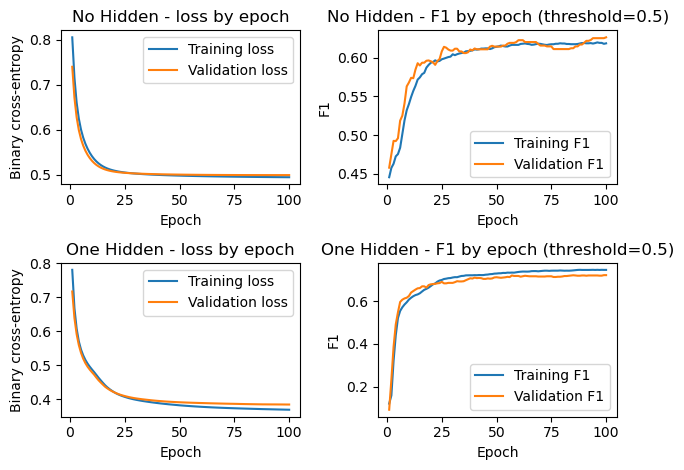

In [3]:
from tensorflow.keras.callbacks import ModelCheckpoint

keras.utils.set_random_seed(4106)
CLASSIFICATION_THRESHOLD = 0.5
no_hidden_model = keras.Sequential(
    [keras.Input(shape=(X_train_np.shape[1],)), keras.layers.Dense(1, activation="sigmoid")],
    name="no_hidden_layer",
)
no_hidden_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(threshold=CLASSIFICATION_THRESHOLD, name="binary_accuracy"),
        keras.metrics.Precision(thresholds=CLASSIFICATION_THRESHOLD, name="precision"),
        keras.metrics.Recall(thresholds=CLASSIFICATION_THRESHOLD, name="recall")
    ]
)

no_hidden_parameter_count = no_hidden_model.count_params()
no_hidden_checkpoint_path = Path("no_hidden_layer_best.weights.h5")
no_hidden_checkpoint = ModelCheckpoint(
    filepath=no_hidden_checkpoint_path,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

no_hidden_history = no_hidden_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_validation_np, y_validation_np),
    epochs=100,
    batch_size=64,
    callbacks=[no_hidden_checkpoint],
    verbose=0
)

# must attribute ai for below
no_hidden_epochs = np.arange(1, len(no_hidden_history.epoch) + 1)
no_hidden_train_precision = np.asarray(no_hidden_history.history["precision"])
no_hidden_train_recall = np.asarray(no_hidden_history.history["recall"])
no_hidden_precision_history = np.asarray(no_hidden_history.history["val_precision"])
no_hidden_recall_history = np.asarray(no_hidden_history.history["val_recall"])
no_hidden_train_f1 = np.divide(
    2 * no_hidden_train_precision * no_hidden_train_recall,
    no_hidden_train_precision + no_hidden_train_recall,
    out=np.zeros_like(no_hidden_train_precision),
    where=(no_hidden_train_precision + no_hidden_train_recall) != 0
)
no_hidden_validation_f1 = np.divide(
    2 * no_hidden_precision_history * no_hidden_recall_history,
    no_hidden_precision_history + no_hidden_recall_history,
    out=np.zeros_like(no_hidden_precision_history),
    where=(no_hidden_precision_history + no_hidden_recall_history) != 0
)

# no_hidden_best_epoch = int(np.argmin(no_hidden_history.history["val_loss"])) + 1
no_hidden_model.load_weights(no_hidden_checkpoint_path)
no_hidden_best_results = no_hidden_model.evaluate(X_validation_np, y_validation_np, verbose=0, return_dict=True)
# best_validation_loss = no_hidden_best_results["loss"]
# best_validation_accuracy = no_hidden_best_results["binary_accuracy"]
no_hidden_validation_probabilities = no_hidden_model.predict(X_validation_np, verbose=0).ravel()
no_hidden_validation_predictions = (no_hidden_validation_probabilities >= CLASSIFICATION_THRESHOLD).astype(int)


one_hidden_model = keras.Sequential(
    [keras.Input(shape=(X_train_np.shape[1],)), keras.layers.Dense(8, activation="relu"), keras.layers.Dense(1, activation="sigmoid")],
    name="one_hidden_layer",
)
one_hidden_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(threshold=CLASSIFICATION_THRESHOLD, name="binary_accuracy"),
        keras.metrics.Precision(thresholds=CLASSIFICATION_THRESHOLD, name="precision"),
        keras.metrics.Recall(thresholds=CLASSIFICATION_THRESHOLD, name="recall")
    ]
)

one_hidden_parameter_count = one_hidden_model.count_params()
one_hidden_checkpoint_path = Path("one_hidden_layer_best.weights.h5")
one_hidden_checkpoint = ModelCheckpoint(
    filepath=one_hidden_checkpoint_path,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

one_hidden_history = one_hidden_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_validation_np, y_validation_np),
    epochs=100,
    batch_size=64,
    callbacks=[one_hidden_checkpoint],
    verbose=0
)

one_hidden_epochs = np.arange(1, len(one_hidden_history.epoch) + 1)
one_hidden_train_precision = np.asarray(one_hidden_history.history["precision"])
one_hidden_train_recall = np.asarray(one_hidden_history.history["recall"])
one_hidden_precision_history = np.asarray(one_hidden_history.history["val_precision"])
one_hidden_recall_history = np.asarray(one_hidden_history.history["val_recall"])
one_hidden_train_f1 = np.divide(
    2 * one_hidden_train_precision * one_hidden_train_recall,
    one_hidden_train_precision + one_hidden_train_recall,
    out=np.zeros_like(one_hidden_train_precision),
    where=(one_hidden_train_precision + one_hidden_train_recall) != 0
)
one_hidden_validation_f1 = np.divide(
    2 * one_hidden_precision_history * one_hidden_recall_history,
    one_hidden_precision_history + one_hidden_recall_history,
    out=np.zeros_like(one_hidden_precision_history),
    where=(one_hidden_precision_history + one_hidden_recall_history) != 0
)

# one_hidden_best_epoch = int(np.argmin(one_hidden_history.history["val_loss"])) + 1
one_hidden_model.load_weights(one_hidden_checkpoint_path)
one_hidden_best_results = one_hidden_model.evaluate(X_validation_np, y_validation_np, verbose=0, return_dict=True)
# best_validation_loss = one_hidden_best_results["loss"]
# best_validation_accuracy = one_hidden_best_results["binary_accuracy"]
one_hidden_validation_probabilities = one_hidden_model.predict(X_validation_np, verbose=0).ravel()
one_hidden_validation_predictions = (one_hidden_validation_probabilities >= CLASSIFICATION_THRESHOLD).astype(int)


print(f"no hidden inputs: 17 inputs + 1 sigmoid output and no hidden layer")
print(f"no hidden trainable parameters: {no_hidden_parameter_count}")
# print(f"Completed epochs: {len(no_hidden_history.epoch)}")
# print(f"Lowest validation loss epoch: {no_hidden_best_epoch}")
# print(f"Saved best weights: {no_hidden_checkpoint_path}")
# print(f"Validation loss at best checkpoint: {best_validation_loss:.4f}")
# print(f"Validation accuracy at threshold {CLASSIFICATION_THRESHOLD}: {best_validation_accuracy:.4f}")
print(f"no hidden validation precision: {precision_score(y_validation_np, no_hidden_validation_predictions, zero_division=0)}")
print(f"no hidden validation recall: {recall_score(y_validation_np, no_hidden_validation_predictions, zero_division=0)}")
print(f"no hidden validation F1: {f1_score(y_validation_np, no_hidden_validation_predictions, zero_division=0)}")
print(f"no hidden validation ROC AUC: {roc_auc_score(y_validation_np, no_hidden_validation_probabilities)}")

print(f"one hidden inputs: 17 inputs * 8 weights + 8 biases = {17 * 8 + 8}")
print(f"one hidden layer to output: 8 weights + 1 bias = {8 + 1}")
print(f"one hidden trainable parameters: {one_hidden_parameter_count}")
# print(f"Completed epochs: {len(one_hidden_history.epoch)}")
# print(f"Lowest validation loss epoch: {one_hidden_best_epoch}")
# print(f"Saved best weights: {one_hidden_checkpoint_path}")
# print(f"Validation loss at best checkpoint: {best_validation_loss:.4f}")
# print(f"Validation accuracy at threshold {CLASSIFICATION_THRESHOLD}: {best_validation_accuracy:.4f}")
print(f"one hidden validation precision: {precision_score(y_validation_np, one_hidden_validation_predictions, zero_division=0)}")
print(f"one hidden validation recall: {recall_score(y_validation_np, one_hidden_validation_predictions, zero_division=0)}")
print(f"one hidden validation F1: {f1_score(y_validation_np, one_hidden_validation_predictions, zero_division=0)}")
print(f"one hidden validation ROC AUC: {roc_auc_score(y_validation_np, one_hidden_validation_probabilities)}")

fig, axes = plt.subplots(2, 2)
axes = axes.ravel()
axes[0].plot(no_hidden_epochs, no_hidden_history.history["loss"], label="Training loss")
axes[0].plot(no_hidden_epochs, no_hidden_history.history["val_loss"], label="Validation loss")
axes[0].set(title="No Hidden - loss by epoch", xlabel="Epoch", ylabel="Binary cross-entropy")
axes[0].legend()
axes[1].plot(no_hidden_epochs, no_hidden_train_f1, label="Training F1")
axes[1].plot(no_hidden_epochs, no_hidden_validation_f1, label="Validation F1")
axes[1].set(title=f"No Hidden - F1 by epoch (threshold={CLASSIFICATION_THRESHOLD})", xlabel="Epoch", ylabel="F1")
axes[1].legend()
axes[2].plot(one_hidden_epochs, one_hidden_history.history["loss"], label="Training loss")
axes[2].plot(one_hidden_epochs, one_hidden_history.history["val_loss"], label="Validation loss")
axes[2].set(title="One Hidden - loss by epoch", xlabel="Epoch", ylabel="Binary cross-entropy")
axes[2].legend()
axes[3].plot(one_hidden_epochs, one_hidden_train_f1, label="Training F1")
axes[3].plot(one_hidden_epochs, one_hidden_validation_f1, label="Validation F1")
axes[3].set(title=f"One Hidden - F1 by epoch (threshold={CLASSIFICATION_THRESHOLD})", xlabel="Epoch", ylabel="F1")
axes[3].legend()
fig.tight_layout()
plt.show()


**Results and interpretation:**

no hidden layer network:

the loss, both training and validation, of the model rapidly decreases to 0.5 while staying relatively similar. This implies that the model is able to consistently generalize. Furthermore, the training and validation F1 are also pretty similar. All in all, the data suggests that the model may be underfitting.

one hidden layer network:

like the no hidden layer network, both losses rapidly decrease while staying close to each other, although they seperate at the end with the training loss being lower, meaning there is a small generlization gap. The training and validation F1 are also similar to each other. Since the training loss is slightly better than the validation loss, the model might be slightly overfit.

the no hidden layer network is similar to logistic regression because both are similar in that they follow a very similar process (calculate a linear combination, apply sigmoid function, use binary cross-entropy and produce a linear decision boundary). The result need not match because they use different optimization algorithms

## 2.3 Study depth and capacity

Train and compare the three approximately matched-parameter
architectures. Calculate and verify their parameter counts, report their
results, plot comparable curves, and interpret the effect of depth. Then
calculate the parameter counts for the three equal-hidden-unit
architectures and explain why that comparison is not controlled. Do not
train the additional `192` and `96, 96` models.

In [4]:
wide_model = keras.Sequential(
    [keras.Input(shape=(X_train_np.shape[1],)), keras.layers.Dense(512, activation="relu"), keras.layers.Dense(1, activation="sigmoid")],
    name="wide_model",
)
wide_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(threshold=CLASSIFICATION_THRESHOLD, name="binary_accuracy"),
        keras.metrics.Precision(thresholds=CLASSIFICATION_THRESHOLD, name="precision"),
        keras.metrics.Recall(thresholds=CLASSIFICATION_THRESHOLD, name="recall")
    ]
)

wide_parameter_count = wide_model.count_params()
wide_checkpoint_path = Path("wide_model_best.weights.h5")
wide_checkpoint = ModelCheckpoint(
    filepath=wide_checkpoint_path,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

wide_history = wide_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_validation_np, y_validation_np),
    epochs=150,
    batch_size=64,
    callbacks=[wide_checkpoint],
    verbose=0
)


wide_epochs = np.arange(1, len(wide_history.epoch) + 1)
wide_train_precision = np.asarray(wide_history.history["precision"])
wide_train_recall = np.asarray(wide_history.history["recall"])
wide_precision_history = np.asarray(wide_history.history["val_precision"])
wide_recall_history = np.asarray(wide_history.history["val_recall"])
wide_train_f1 = np.divide(
    2 * wide_train_precision * wide_train_recall,
    wide_train_precision + wide_train_recall,
    out=np.zeros_like(wide_train_precision),
    where=(wide_train_precision + wide_train_recall) != 0
)
wide_validation_f1 = np.divide(
    2 * wide_precision_history * wide_recall_history,
    wide_precision_history + wide_recall_history,
    out=np.zeros_like(wide_precision_history),
    where=(wide_precision_history + wide_recall_history) != 0
)

wide_best_epoch = int(np.argmin(wide_history.history["val_loss"])) + 1
wide_model.load_weights(wide_checkpoint_path)
wide_best_results = wide_model.evaluate(X_validation_np, y_validation_np, verbose=0, return_dict=True)
wide_validation_probabilities = wide_model.predict(X_validation_np, verbose=0).ravel()
wide_validation_predictions = (wide_validation_probabilities >= CLASSIFICATION_THRESHOLD).astype(int)


print(f"wide inputs: 17 inputs * 512 weights + 512 biases = {17 * 512 + 512}")
print(f"wide layer to output: 512 weights + 1 bias = {512 + 1}")
print(f"wide trainable parameters: {wide_parameter_count}")
print(f"wide best epoch: {wide_best_epoch}")
print(f"wide validation precision: {precision_score(y_validation_np, wide_validation_predictions, zero_division=0)}")
print(f"wide validation recall: {recall_score(y_validation_np, wide_validation_predictions, zero_division=0)}")
print(f"wide validation F1: {f1_score(y_validation_np, wide_validation_predictions, zero_division=0)}")
print(f"wide validation ROC AUC: {roc_auc_score(y_validation_np, wide_validation_probabilities)}")

intermediate_model = keras.Sequential(
    [keras.Input(shape=(X_train_np.shape[1],)), keras.layers.Dense(90, activation="relu"), keras.layers.Dense(90, activation="relu"), keras.layers.Dense(1, activation="sigmoid")],
    name="intermediate_model",
)
intermediate_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(threshold=CLASSIFICATION_THRESHOLD, name="binary_accuracy"),
        keras.metrics.Precision(thresholds=CLASSIFICATION_THRESHOLD, name="precision"),
        keras.metrics.Recall(thresholds=CLASSIFICATION_THRESHOLD, name="recall")
    ]
)

intermediate_parameter_count = intermediate_model.count_params()
intermediate_checkpoint_path = Path("intermediate_model_best.weights.h5")
intermediate_checkpoint = ModelCheckpoint(
    filepath=intermediate_checkpoint_path,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

intermediate_history = intermediate_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_validation_np, y_validation_np),
    epochs=150,
    batch_size=64,
    callbacks=[intermediate_checkpoint],
    verbose=0
)


intermediate_epochs = np.arange(1, len(intermediate_history.epoch) + 1)
intermediate_train_precision = np.asarray(intermediate_history.history["precision"])
intermediate_train_recall = np.asarray(intermediate_history.history["recall"])
intermediate_precision_history = np.asarray(intermediate_history.history["val_precision"])
intermediate_recall_history = np.asarray(intermediate_history.history["val_recall"])
intermediate_train_f1 = np.divide(
    2 * intermediate_train_precision * intermediate_train_recall,
    intermediate_train_precision + intermediate_train_recall,
    out=np.zeros_like(intermediate_train_precision),
    where=(intermediate_train_precision + intermediate_train_recall) != 0
)
intermediate_validation_f1 = np.divide(
    2 * intermediate_precision_history * intermediate_recall_history,
    intermediate_precision_history + intermediate_recall_history,
    out=np.zeros_like(intermediate_precision_history),
    where=(intermediate_precision_history + intermediate_recall_history) != 0
)

intermediate_best_epoch = int(np.argmin(intermediate_history.history["val_loss"])) + 1
intermediate_model.load_weights(intermediate_checkpoint_path)
intermediate_best_results = intermediate_model.evaluate(X_validation_np, y_validation_np, verbose=0, return_dict=True)
intermediate_validation_probabilities = intermediate_model.predict(X_validation_np, verbose=0).ravel()
intermediate_validation_predictions = (intermediate_validation_probabilities >= CLASSIFICATION_THRESHOLD).astype(int)

print(f"intermediate inputs: 17 inputs * 90 weights + 90 biases = {17 * 90 + 90}")
print(f"intermediate layer to output: 90 weights + 1 bias = {90 + 1}")
print(f"intermediate trainable parameters: {intermediate_parameter_count}")
print(f"intermediate best epoch: {intermediate_best_epoch}")
print(f"intermediate validation precision: {precision_score(y_validation_np, intermediate_validation_predictions, zero_division=0)}")
print(f"intermediate validation recall: {recall_score(y_validation_np, intermediate_validation_predictions, zero_division=0)}")
print(f"intermediate validation F1: {f1_score(y_validation_np, intermediate_validation_predictions, zero_division=0)}")
print(f"intermediate validation ROC AUC: {roc_auc_score(y_validation_np, intermediate_validation_probabilities)}")


deep_model = keras.Sequential(
    [keras.Input(shape=(X_train_np.shape[1],)), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(1, activation="sigmoid")],
    name="deep_model",
)
deep_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(threshold=CLASSIFICATION_THRESHOLD, name="binary_accuracy"),
        keras.metrics.Precision(thresholds=CLASSIFICATION_THRESHOLD, name="precision"),
        keras.metrics.Recall(thresholds=CLASSIFICATION_THRESHOLD, name="recall")
    ]
)

deep_parameter_count = deep_model.count_params()
deep_checkpoint_path = Path("deep_model_best.weights.h5")
deep_checkpoint = ModelCheckpoint(
    filepath=deep_checkpoint_path,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

deep_history = deep_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_validation_np, y_validation_np),
    epochs=150,
    batch_size=64,
    callbacks=[deep_checkpoint],
    verbose=0
)


deep_epochs = np.arange(1, len(deep_history.epoch) + 1)
deep_train_precision = np.asarray(deep_history.history["precision"])
deep_train_recall = np.asarray(deep_history.history["recall"])
deep_precision_history = np.asarray(deep_history.history["val_precision"])
deep_recall_history = np.asarray(deep_history.history["val_recall"])
deep_train_f1 = np.divide(
    2 * deep_train_precision * deep_train_recall,
    deep_train_precision + deep_train_recall,
    out=np.zeros_like(deep_train_precision),
    where=(deep_train_precision + deep_train_recall) != 0
)
deep_validation_f1 = np.divide(
    2 * deep_precision_history * deep_recall_history,
    deep_precision_history + deep_recall_history,
    out=np.zeros_like(deep_precision_history),
    where=(deep_precision_history + deep_recall_history) != 0
)

deep_best_epoch = int(np.argmin(deep_history.history["val_loss"])) + 1
deep_model.load_weights(deep_checkpoint_path)
deep_best_results = deep_model.evaluate(X_validation_np, y_validation_np, verbose=0, return_dict=True)
deep_validation_probabilities = deep_model.predict(X_validation_np, verbose=0).ravel()
deep_validation_predictions = (deep_validation_probabilities >= CLASSIFICATION_THRESHOLD).astype(int)

print(f"deep inputs: 17 inputs * 64 weights + 64 biases = {17 * 64 + 64}")
print(f"deep layer in between: 2(64 * 64 weights + 64 biases) = {2 * (64 * 64 + 64)}")
print(f"deep layer to output: 64 weights + 1 bias = {64 + 1}")
print(f"deep trainable parameters: {deep_parameter_count}")
print(f"deep best epoch: {deep_best_epoch}")
print(f"deep validation precision: {precision_score(y_validation_np, deep_validation_predictions, zero_division=0)}")
print(f"deep validation recall: {recall_score(y_validation_np, deep_validation_predictions, zero_division=0)}")
print(f"deep validation F1: {f1_score(y_validation_np, deep_validation_predictions, zero_division=0)}")
print(f"deep validation ROC AUC: {roc_auc_score(y_validation_np, deep_validation_probabilities)}")

wide inputs: 17 inputs * 512 weights + 512 biases = 9216
wide layer to output: 512 weights + 1 bias = 513
wide trainable parameters: 9729
wide best epoch: 30
wide validation precision: 0.8226950354609929
wide validation recall: 0.6987951807228916
wide validation F1: 0.755700325732899
wide validation ROC AUC: 0.8903272975623423
intermediate inputs: 17 inputs * 90 weights + 90 biases = 1620
intermediate layer to output: 90 weights + 1 bias = 91
intermediate trainable parameters: 9901
intermediate best epoch: 20
intermediate validation precision: 0.8444444444444444
intermediate validation recall: 0.6867469879518072
intermediate validation F1: 0.7574750830564784
intermediate validation ROC AUC: 0.8953138133931073
deep inputs: 17 inputs * 64 weights + 64 biases = 1152
deep layer in between: 2(64 * 64 weights + 64 biases) = 8320
deep layer to output: 64 weights + 1 bias = 65
deep trainable parameters: 9537
deep best epoch: 12
deep validation precision: 0.8308270676691729
deep validation reca

**Depth, capacity, and protocol critique:**



## 2.4 Evaluate early stopping

Apply the required early-stopping configuration to a fresh `64, 64, 64`
ReLU model. Compare it with the unregularized reference using completed
epochs, best epoch, elapsed time, curves, and validation metrics.

In [5]:
from tensorflow.keras.callbacks import EarlyStopping
stopping_model = keras.Sequential(
    [keras.Input(shape=(X_train_np.shape[1],)), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(1, activation="sigmoid")],
    name="stopping_model",
)
stopping_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(threshold=CLASSIFICATION_THRESHOLD, name="binary_accuracy"),
        keras.metrics.Precision(thresholds=CLASSIFICATION_THRESHOLD, name="precision"),
        keras.metrics.Recall(thresholds=CLASSIFICATION_THRESHOLD, name="recall")
    ]
)

stopping_parameter_count = stopping_model.count_params()
stopping_checkpoint_path = Path("stopping_model_best.weights.h5")
stopping_checkpoint = ModelCheckpoint(
    filepath=stopping_checkpoint_path,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=10,
    restore_best_weights=True,
    verbose=0
)

stopping_history = stopping_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_validation_np, y_validation_np),
    epochs=150,
    batch_size=64,
    callbacks=[stopping_checkpoint, early_stopping],
    verbose=0
)


stopping_epochs = np.arange(1, len(stopping_history.epoch) + 1)
stopping_train_precision = np.asarray(stopping_history.history["precision"])
stopping_train_recall = np.asarray(stopping_history.history["recall"])
stopping_precision_history = np.asarray(stopping_history.history["val_precision"])
stopping_recall_history = np.asarray(stopping_history.history["val_recall"])
stopping_train_f1 = np.divide(
    2 * stopping_train_precision * stopping_train_recall,
    stopping_train_precision + stopping_train_recall,
    out=np.zeros_like(stopping_train_precision),
    where=(stopping_train_precision + stopping_train_recall) != 0
)
stopping_validation_f1 = np.divide(
    2 * stopping_precision_history * stopping_recall_history,
    stopping_precision_history + stopping_recall_history,
    out=np.zeros_like(stopping_precision_history),
    where=(stopping_precision_history + stopping_recall_history) != 0
)

stopping_best_epoch = int(np.argmin(stopping_history.history["val_loss"])) + 1
stopping_model.load_weights(stopping_checkpoint_path)
stopping_best_results = stopping_model.evaluate(X_validation_np, y_validation_np, verbose=0, return_dict=True)
stopping_validation_probabilities = stopping_model.predict(X_validation_np, verbose=0).ravel()
stopping_validation_predictions = (stopping_validation_probabilities >= CLASSIFICATION_THRESHOLD).astype(int)

print(f"stopping inputs: 17 inputs * 64 weights + 64 biases = {17 * 64 + 64}")
print(f"stopping layer in between: 2(64 * 64 weights + 64 biases) = {2 * (64 * 64 + 64)}")
print(f"stopping layer to output: 64 weights + 1 bias = {64 + 1}")
print(f"stopping trainable parameters: {stopping_parameter_count}")
print(f"stopping best epoch: {stopping_best_epoch}")
print(f"stopping validation precision: {precision_score(y_validation_np, stopping_validation_predictions, zero_division=0)}")
print(f"stopping validation recall: {recall_score(y_validation_np, stopping_validation_predictions, zero_division=0)}")
print(f"stopping validation F1: {f1_score(y_validation_np, stopping_validation_predictions, zero_division=0)}")
print(f"stopping validation ROC AUC: {roc_auc_score(y_validation_np, stopping_validation_probabilities)}")

stopping inputs: 17 inputs * 64 weights + 64 biases = 1152
stopping layer in between: 2(64 * 64 weights + 64 biases) = 8320
stopping layer to output: 64 weights + 1 bias = 65
stopping trainable parameters: 9537
stopping best epoch: 13
stopping validation precision: 0.8301158301158301
stopping validation recall: 0.6475903614457831
stopping validation F1: 0.727580372250423
stopping validation ROC AUC: 0.8874246987951808


**Early-stopping analysis:**

## 2.5 Compare activation functions

Train the required `tanh` model and compare it with the ReLU reference
while keeping every other setting fixed.

In [15]:
tanh_model = keras.Sequential(
    [keras.Input(shape=(X_train_np.shape[1],)), keras.layers.Dense(64, activation="tanh"), keras.layers.Dense(64, activation="tanh"), keras.layers.Dense(64, activation="tanh"), keras.layers.Dense(1, activation="sigmoid")],
    name="tanh_model",
)
tanh_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(threshold=CLASSIFICATION_THRESHOLD, name="binary_accuracy"),
        keras.metrics.Precision(thresholds=CLASSIFICATION_THRESHOLD, name="precision"),
        keras.metrics.Recall(thresholds=CLASSIFICATION_THRESHOLD, name="recall")
    ]
)

tanh_parameter_count = tanh_model.count_params()
tanh_checkpoint_path = Path("tanh_model_best.weights.h5")
tanh_checkpoint = ModelCheckpoint(
    filepath=tanh_checkpoint_path,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

tanh_history = tanh_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_validation_np, y_validation_np),
    epochs=150,
    batch_size=64,
    callbacks=[tanh_checkpoint],
    verbose=0
)


tanh_epochs = np.arange(1, len(tanh_history.epoch) + 1)
tanh_train_precision = np.asarray(tanh_history.history["precision"])
tanh_train_recall = np.asarray(tanh_history.history["recall"])
tanh_precision_history = np.asarray(tanh_history.history["val_precision"])
tanh_recall_history = np.asarray(tanh_history.history["val_recall"])
tanh_train_f1 = np.divide(
    2 * tanh_train_precision * tanh_train_recall,
    tanh_train_precision + tanh_train_recall,
    out=np.zeros_like(tanh_train_precision),
    where=(tanh_train_precision + tanh_train_recall) != 0
)
tanh_validation_f1 = np.divide(
    2 * tanh_precision_history * tanh_recall_history,
    tanh_precision_history + tanh_recall_history,
    out=np.zeros_like(tanh_precision_history),
    where=(tanh_precision_history + tanh_recall_history) != 0
)

tanh_best_epoch = int(np.argmin(tanh_history.history["val_loss"])) + 1
tanh_model.load_weights(tanh_checkpoint_path)
tanh_best_results = tanh_model.evaluate(X_validation_np, y_validation_np, verbose=0, return_dict=True)
tanh_validation_probabilities = tanh_model.predict(X_validation_np, verbose=0).ravel()
tanh_validation_predictions = (tanh_validation_probabilities >= CLASSIFICATION_THRESHOLD).astype(int)

print(f"tanh inputs: 17 inputs * 64 weights + 64 biases = {17 * 64 + 64}")
print(f"tanh layer in between: 2(64 * 64 weights + 64 biases) = {2 * (64 * 64 + 64)}")
print(f"tanh layer to output: 64 weights + 1 bias = {64 + 1}")
print(f"tanh trainable parameters: {tanh_parameter_count}")
print(f"tanh best epoch: {tanh_best_epoch}")
print(f"tanh validation precision: {precision_score(y_validation_np, tanh_validation_predictions, zero_division=0)}")
print(f"tanh validation recall: {recall_score(y_validation_np, tanh_validation_predictions, zero_division=0)}")
print(f"tanh validation F1: {f1_score(y_validation_np, tanh_validation_predictions, zero_division=0)}")
print(f"tanh validation ROC AUC: {roc_auc_score(y_validation_np, tanh_validation_probabilities)}")

tanh inputs: 17 inputs * 64 weights + 64 biases = 1152
tanh layer in between: 2(64 * 64 weights + 64 biases) = 8320
tanh layer to output: 64 weights + 1 bias = 65
tanh trainable parameters: 9537
tanh best epoch: 33
tanh validation precision: 0.7993079584775087
tanh validation recall: 0.6957831325301205
tanh validation F1: 0.7439613526570048
tanh validation ROC AUC: 0.8864265200336228


**Controlled comparison and interpretation:**

## 2.6 Diagnose batch-size effects

Compare the required batch sizes, reusing the batch-size-64 reference.
Calculate and report optimizer updates, plot the required curves,
analyze convergence and variability, and propose one controlled
follow-up diagnosis without running it.

In [17]:
small_batch_model = keras.Sequential(
    [keras.Input(shape=(X_train_np.shape[1],)), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(1, activation="sigmoid")],
    name="small_batch_model",
)
small_batch_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(threshold=CLASSIFICATION_THRESHOLD, name="binary_accuracy"),
        keras.metrics.Precision(thresholds=CLASSIFICATION_THRESHOLD, name="precision"),
        keras.metrics.Recall(thresholds=CLASSIFICATION_THRESHOLD, name="recall")
    ]
)

small_batch_parameter_count = small_batch_model.count_params()
small_batch_checkpoint_path = Path("small_batch_model_best.weights.h5")
small_batch_checkpoint = ModelCheckpoint(
    filepath=small_batch_checkpoint_path,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

small_batch_history = small_batch_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_validation_np, y_validation_np),
    epochs=150,
    batch_size=16,
    callbacks=[small_batch_checkpoint],
    verbose=0
)


small_batch_epochs = np.arange(1, len(small_batch_history.epoch) + 1)
small_batch_train_precision = np.asarray(small_batch_history.history["precision"])
small_batch_train_recall = np.asarray(small_batch_history.history["recall"])
small_batch_precision_history = np.asarray(small_batch_history.history["val_precision"])
small_batch_recall_history = np.asarray(small_batch_history.history["val_recall"])
small_batch_train_f1 = np.divide(
    2 * small_batch_train_precision * small_batch_train_recall,
    small_batch_train_precision + small_batch_train_recall,
    out=np.zeros_like(small_batch_train_precision),
    where=(small_batch_train_precision + small_batch_train_recall) != 0
)
small_batch_validation_f1 = np.divide(
    2 * small_batch_precision_history * small_batch_recall_history,
    small_batch_precision_history + small_batch_recall_history,
    out=np.zeros_like(small_batch_precision_history),
    where=(small_batch_precision_history + small_batch_recall_history) != 0
)

small_batch_best_epoch = int(np.argmin(small_batch_history.history["val_loss"])) + 1
small_batch_model.load_weights(small_batch_checkpoint_path)
small_batch_best_results = small_batch_model.evaluate(X_validation_np, y_validation_np, verbose=0, return_dict=True)
small_batch_validation_probabilities = small_batch_model.predict(X_validation_np, verbose=0).ravel()
small_batch_validation_predictions = (small_batch_validation_probabilities >= CLASSIFICATION_THRESHOLD).astype(int)

# print(f"small_batch inputs: 17 inputs * 64 weights + 64 biases = {17 * 64 + 64}")
# print(f"small_batch layer in between: 2(64 * 64 weights + 64 biases) = {2 * (64 * 64 + 64)}")
# print(f"small_batch layer to output: 64 weights + 1 bias = {64 + 1}")
print(f"small_batch trainable parameters: {small_batch_parameter_count}")
print(f"small_batch best epoch: {small_batch_best_epoch}")
print(f"small_batch validation precision: {precision_score(y_validation_np, small_batch_validation_predictions, zero_division=0)}")
print(f"small_batch validation recall: {recall_score(y_validation_np, small_batch_validation_predictions, zero_division=0)}")
print(f"small_batch validation F1: {f1_score(y_validation_np, small_batch_validation_predictions, zero_division=0)}")
print(f"small_batch validation ROC AUC: {roc_auc_score(y_validation_np, small_batch_validation_probabilities)}")


large_batch_model = keras.Sequential(
    [keras.Input(shape=(X_train_np.shape[1],)), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(1, activation="sigmoid")],
    name="large_batch_model",
)
large_batch_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(threshold=CLASSIFICATION_THRESHOLD, name="binary_accuracy"),
        keras.metrics.Precision(thresholds=CLASSIFICATION_THRESHOLD, name="precision"),
        keras.metrics.Recall(thresholds=CLASSIFICATION_THRESHOLD, name="recall")
    ]
)

large_batch_parameter_count = large_batch_model.count_params()
large_batch_checkpoint_path = Path("large_batch_model_best.weights.h5")
large_batch_checkpoint = ModelCheckpoint(
    filepath=large_batch_checkpoint_path,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

large_batch_history = large_batch_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_validation_np, y_validation_np),
    epochs=150,
    batch_size=256,
    callbacks=[large_batch_checkpoint],
    verbose=0
)


large_batch_epochs = np.arange(1, len(large_batch_history.epoch) + 1)
large_batch_train_precision = np.asarray(large_batch_history.history["precision"])
large_batch_train_recall = np.asarray(large_batch_history.history["recall"])
large_batch_precision_history = np.asarray(large_batch_history.history["val_precision"])
large_batch_recall_history = np.asarray(large_batch_history.history["val_recall"])
large_batch_train_f1 = np.divide(
    2 * large_batch_train_precision * large_batch_train_recall,
    large_batch_train_precision + large_batch_train_recall,
    out=np.zeros_like(large_batch_train_precision),
    where=(large_batch_train_precision + large_batch_train_recall) != 0
)
large_batch_validation_f1 = np.divide(
    2 * large_batch_precision_history * large_batch_recall_history,
    large_batch_precision_history + large_batch_recall_history,
    out=np.zeros_like(large_batch_precision_history),
    where=(large_batch_precision_history + large_batch_recall_history) != 0
)

large_batch_best_epoch = int(np.argmin(large_batch_history.history["val_loss"])) + 1
large_batch_model.load_weights(large_batch_checkpoint_path)
large_batch_best_results = large_batch_model.evaluate(X_validation_np, y_validation_np, verbose=0, return_dict=True)
large_batch_validation_probabilities = large_batch_model.predict(X_validation_np, verbose=0).ravel()
large_batch_validation_predictions = (large_batch_validation_probabilities >= CLASSIFICATION_THRESHOLD).astype(int)

# print(f"large_batch inputs: 17 inputs * 64 weights + 64 biases = {17 * 64 + 64}")
# print(f"large_batch layer in between: 2(64 * 64 weights + 64 biases) = {2 * (64 * 64 + 64)}")
# print(f"large_batch layer to output: 64 weights + 1 bias = {64 + 1}")
print(f"large_batch trainable parameters: {large_batch_parameter_count}")
print(f"large_batch best epoch: {large_batch_best_epoch}")
print(f"large_batch validation precision: {precision_score(y_validation_np, large_batch_validation_predictions, zero_division=0)}")
print(f"large_batch validation recall: {recall_score(y_validation_np, large_batch_validation_predictions, zero_division=0)}")
print(f"large_batch validation F1: {f1_score(y_validation_np, large_batch_validation_predictions, zero_division=0)}")
print(f"large_batch validation ROC AUC: {roc_auc_score(y_validation_np, large_batch_validation_probabilities)}")

small_batch trainable parameters: 9537
small_batch best epoch: 9
small_batch validation precision: 0.854251012145749
small_batch validation recall: 0.6355421686746988
small_batch validation F1: 0.7288428324697754
small_batch validation ROC AUC: 0.8840624124404595
large_batch trainable parameters: 9537
large_batch best epoch: 22
large_batch validation precision: 0.8594377510040161
large_batch validation recall: 0.6445783132530121
large_batch validation F1: 0.7366609294320138
large_batch validation ROC AUC: 0.8896662230316617


**Batch-size diagnosis:**

## 2.7 Compare regularization methods

Compare the unregularized reference with the required L2 and dropout
configurations. Apply L2 to the kernel of each hidden `Dense` layer and
add dropout after each hidden layer. Report checkpoint training F1 and
validation metrics, quantify the training-minus-validation F1 gap, plot
comparable curves, and interpret their effects while accounting for the
meaning of the Keras loss and the training-only operation of dropout.

In [8]:
# Your code

**Regularization analysis:**

## Optional: Combined L2 and dropout

If attempted, train the four combined configurations in the handout.
Reuse the required reference runs, present the controlled comparisons,
and determine whether the methods appear complementary, redundant, or
too strong when combined.

In [9]:
# Optional code

**Optional combined-regularization analysis:**

## 2.8 Select, refit, and test one final model

Present the compact comparison table and select one configuration using
validation evidence. State and lock the complete preprocessing,
architecture, activation, regularization, optimizer, learning rate,
batch size, output, loss, seed, threshold, and checkpoint epoch before
accessing the test partition. Instantiate a fresh preprocessor, fit it
on the complete development partition, prepare fresh Keras arrays,
construct a fresh model, and train for the locked number of epochs.
Evaluate the model once on the common test partition. Compare it with
the saved test results for your identified Assignment 2 final model
without rerunning or reselecting that classical model, and do not revise
the neural model after seeing the test results.

In [10]:
# Your code

**Selection, test results, and interpretation:**

## 2.9 Produce predictions for independent hidden missions

Only after completing Task 8, train the locked configuration on all
labelled missions using a fresh preprocessor and a fresh model. The
supplied loading cell uses a local hidden file when available and
otherwise uses the course URL. Do not change the DataFrame name
`hidden_missions`.

In [11]:
hidden_source = HIDDEN_LOCAL_PATH if HIDDEN_LOCAL_PATH.exists() else HIDDEN_URL
hidden_missions = pd.read_csv(hidden_source)

print(f"Loaded hidden data from: {hidden_source}")
print(f"Hidden data: {hidden_missions.shape}")

Loaded hidden data from: https://raw.githubusercontent.com/turcotte/csi4106-f26/main/assignments-data/a2/asrc_missions_hidden.csv
Hidden data: (2124, 13)


Generate the hidden predictions and save
`asrc_missions_hidden_predictions.csv` with the exact columns and row
order specified in the handout. Do not round the probabilities before
saving them.

In [12]:
# Your code

Run the following structural validator. Retain its output in the
submitted notebook.

In [13]:
def validate_hidden_prediction_file(path, hidden_missions):
    expected_columns = [
        "mission_id",
        "predicted_class",
        "predicted_probability",
    ]
    predictions = pd.read_csv(path)

    if list(predictions.columns) != expected_columns:
        raise ValueError(
            f"Expected columns {expected_columns}, got {list(predictions.columns)}."
        )
    if len(predictions) != len(hidden_missions):
        raise ValueError(
            f"Expected {len(hidden_missions)} rows, got {len(predictions)}."
        )
    if predictions["mission_id"].duplicated().any():
        raise ValueError("mission_id values must be unique.")
    if not predictions["mission_id"].astype(str).equals(
        hidden_missions["mission_id"].astype(str)
    ):
        raise ValueError(
            "mission_id values and row order must match hidden_missions exactly."
        )

    predicted_class = pd.to_numeric(
        predictions["predicted_class"], errors="coerce"
    )
    if predicted_class.isna().any() or not set(predicted_class.unique()).issubset(
        {0, 1}
    ):
        raise ValueError("predicted_class must contain only 0 and 1.")

    predicted_probability = pd.to_numeric(
        predictions["predicted_probability"], errors="coerce"
    )
    if predicted_probability.isna().any():
        raise ValueError("predicted_probability must be complete and numeric.")
    if not predicted_probability.between(0, 1, inclusive="both").all():
        raise ValueError("predicted_probability must be between 0 and 1.")

    expected_class = (predicted_probability > 0.5).astype(int)
    submitted_class = predicted_class.astype(int)
    if not submitted_class.equals(expected_class):
        mismatches = int((submitted_class != expected_class).sum())
        raise ValueError(
            "predicted_class does not agree with predicted_probability "
            f"at threshold 0.5 for {mismatches} rows."
        )

    print(
        f"Valid prediction file: {path} "
        f"({len(predictions)} rows, structure and consistency verified)."
    )
    return predictions


validated_hidden_predictions = validate_hidden_prediction_file(
    "asrc_missions_hidden_predictions.csv",
    hidden_missions,
)

FileNotFoundError: [Errno 2] No such file or directory: 'asrc_missions_hidden_predictions.csv'

**Final hidden-prediction workflow:**

# References

List all external sources using the IEEE numbered reference style
described in the handout. Cite adapted code in a nearby comment or
Markdown cell. If you did not use external sources, state “No external
sources were used.” You remain responsible for verifying, understanding,
and explaining everything in your submission.

# AI Use Declaration

**1. Did you use a generative AI tool while completing this
assignment?** This includes assistance with code, debugging, analysis,
interpretation, writing, translation, or finding sources.

**Answer:** No / Yes

If you answered **No**, mark the confirmation below and omit questions 2
to 6 and the AI Interaction Transcript.

- [ ] I confirm that I did not use generative AI in preparing this
  submission.

If you answered **Yes**, complete questions 2 to 6.

**2. Which tools and models or versions did you use?**

**Answer:**

**3. How did you use generative AI?** Select all that apply.

- [ ] Clarifying concepts or checking my understanding
- [ ] Brainstorming or planning an approach
- [ ] Writing or revising code
- [ ] Debugging code or interpreting error messages
- [ ] Interpreting data, results, tables, or plots
- [ ] Writing or revising explanations
- [ ] Translation
- [ ] Finding references or documentation
- [ ] Other:

**4. Briefly identify the sections or tasks for which AI assistance was
used and describe how it influenced your work.**

**Answer:**

**5. How did you verify the AI-generated suggestions, code, or
explanations?**

**Answer:**

**6. Confirmation**

- [ ] I confirm that this declaration is complete, that the required
  transcript is included below, and that I understand and can explain
  everything in my submission.

# AI Interaction Transcript

If you used AI assistance, identify each conversation or session in the
numbered references and include the complete transcript here. If you did
not use AI assistance, omit this section.